# Imports

In [2]:
%matplotlib inline
import pandas as pd
import numpy as np
from init_df import body_df, title_df
from datetime import date
import matplotlib.pyplot as plt
import seaborn as sns
import math
from statsmodels.stats import diagnostic
from scipy import stats
import statsmodels.api as sm
import statsmodels.formula.api as smf

In [3]:
body_df

,SOURCE_SUBREDDIT,TARGET_SUBREDDIT,POST_ID,TIMESTAMP,LINK_SENTIMENT,Number of characters,Number of characters without counting white space,Fraction of alphabetical characters,Fraction of digits,Fraction of uppercase characters,...,LIWC_Achiev,LIWC_Leisure,LIWC_Home,LIWC_Money,LIWC_Relig,LIWC_Death,LIWC_Assent,LIWC_Dissent,LIWC_Nonflu,LIWC_Filler
0,leagueoflegends,teamredditteams,1u4nrps,2013-12-31 16:39:58,1,345.0,298.0,0.756522,0.017391,0.086957,...,0.068966,0.034483,0.0,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
1,theredlion,soccer,1u4qkd,2013-12-31 18:18:37,-1,101.0,98.0,0.742574,0.019802,0.049505,...,0.000000,0.066667,0.0,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
2,inlandempire,bikela,1u4qlzs,2014-01-01 14:54:35,1,85.0,85.0,0.752941,0.023529,0.082353,...,0.000000,0.000000,0.0,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
3,nfl,cfb,1u4sjvs,2013-12-31 17:37:55,1,1124.0,949.0,0.772242,0.001779,0.057829,...,0.031250,0.020833,0.0,0.000000,0.000000,0.000000,0.000000,0.000000,0.020833,0.005208
4,playmygame,gamedev,1u4w5ss,2014-01-01 02:51:13,1,715.0,622.0,0.777622,0.006993,0.025175,...,0.016667,0.025000,0.0,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.008333
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
286556,negareddit,debatefascism,68im20s,2017-04-30 16:31:26,1,441.0,405.0,0.775510,0.029478,0.022676,...,0.000000,0.000000,0.0,0.000000,0.015385,0.000000,0.000000,0.000000,0.000000,0.015385
286557,mildlynomil,justnomil,68imlas,2017-04-30 04:19:03,1,2226.0,1855.0,0.786164,0.002246,0.045822,...,0.007634,0.022901,0.0,0.005089,0.002545,0.007634,0.000000,0.000000,0.002545,0.002545
286558,mmorpg,blackdesertonline,68ip5os,2017-04-30 16:54:08,1,1100.0,909.0,0.778182,0.001818,0.023636,...,0.019704,0.034483,0.0,0.000000,0.014778,0.000000,0.004926,0.000000,0.009852,0.004926
286559,electricskateboards,askreddit,68ipb2s,2017-04-30 16:41:53,1,1876.0,1567.0,0.781450,0.006930,0.019723,...,0.021021,0.000000,0.0,0.000000,0.000000,0.000000,0.003003,0.000000,0.000000,0.000000


In [4]:
title_df

,SOURCE_SUBREDDIT,TARGET_SUBREDDIT,POST_ID,TIMESTAMP,LINK_SENTIMENT,Number of characters,Number of characters without counting white space,Fraction of alphabetical characters,Fraction of digits,Fraction of uppercase characters,...,LIWC_Achiev,LIWC_Leisure,LIWC_Home,LIWC_Money,LIWC_Relig,LIWC_Death,LIWC_Assent,LIWC_Dissent,LIWC_Nonflu,LIWC_Filler
0,rddtgaming,rddtrust,1u4pzzs,2013-12-31 16:39:18,1,25.0,23.0,0.760000,0.000000,0.440000,...,0.000000,0.00,0.00,0.0,0.0,0.0,0.0,0.0,0.0,0.00
1,xboxone,battlefield_4,1u4tmfs,2013-12-31 17:59:11,1,100.0,88.0,0.780000,0.020000,0.080000,...,0.058824,0.00,0.00,0.0,0.0,0.0,0.0,0.0,0.0,0.00
2,ps4,battlefield_4,1u4tmos,2013-12-31 17:59:40,1,100.0,88.0,0.780000,0.020000,0.080000,...,0.058824,0.00,0.00,0.0,0.0,0.0,0.0,0.0,0.0,0.00
3,fitnesscirclejerk,leangains,1u50xfs,2013-12-31 19:01:56,1,49.0,43.0,0.775510,0.000000,0.265306,...,0.000000,0.00,0.00,0.0,0.0,0.0,0.0,0.0,0.0,0.00
4,fitnesscirclejerk,lifeprotips,1u51nps,2013-12-31 21:02:28,1,14.0,14.0,0.785714,0.000000,0.428571,...,0.000000,0.00,0.00,0.0,0.0,0.0,0.0,0.0,0.0,0.00
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
571922,seattleshitshow,seattlewa,68iptp,2017-04-27 11:07:31,-1,83.0,70.0,0.783133,0.000000,0.108434,...,0.000000,0.00,0.00,0.0,0.0,0.0,0.0,0.0,0.0,0.00
571923,peoplewhosayheck,spiderman,68iqh6s,2017-04-30 16:36:07,1,121.0,105.0,0.719008,0.016529,0.099174,...,0.000000,0.05,0.00,0.0,0.0,0.0,0.0,0.0,0.0,0.00
571924,vzla,wtf,68iqkcs,2017-04-30 15:50:07,1,68.0,58.0,0.764706,0.000000,0.147059,...,0.000000,0.00,0.00,0.0,0.0,0.0,0.0,0.0,0.0,0.00
571925,denverbroncos,nfl,68iqt8,2017-04-30 16:11:30,-1,96.0,79.0,0.770833,0.000000,0.072917,...,0.000000,0.00,0.05,0.0,0.0,0.0,0.0,0.0,0.0,0.05


# Toxicity Birth analysis

## Emergence from a major event
### GAMERGATE (AUGUST 2014)

In [121]:
# Subreddit keyword to focus on
keyword = "nba"

# Time Window to consider
time_window = [date(2015, 6, 1), date(2015, 8, 1)]

# Create a new columns based on DATETIME for both df
body_df["DATETIME"] = pd.to_datetime(body_df["TIMESTAMP"])
title_df["DATETIME"] = pd.to_datetime(title_df["TIMESTAMP"])

body_df["DAY"] = body_df["DATETIME"].dt.date
body_df["MONTH"] = body_df["DATETIME"].dt.to_period("M")
title_df["DAY"] = title_df["DATETIME"].dt.date
title_df["MONTH"] = title_df["DATETIME"].dt.to_period("M")

# Extract focused df from keyword and time window
focused_body_df = body_df[
    (
        body_df["SOURCE_SUBREDDIT"].str.contains(keyword, case=False, na=False) |
        body_df["TARGET_SUBREDDIT"].str.contains(keyword, case=False, na=False)
    ) &
    (body_df["DATETIME"].dt.date >= time_window[0]) &
    (body_df["DATETIME"].dt.date <= time_window[1])
]
focused_title_df = body_df[
    (
        title_df["SOURCE_SUBREDDIT"].str.contains(keyword, case=False, na=False) |
        title_df["TARGET_SUBREDDIT"].str.contains(keyword, case=False, na=False)
    ) &
    (title_df["DATETIME"].dt.date >= time_window[0]) &
    (title_df["DATETIME"].dt.date <= time_window[1])
]

focused_body_df.head(10)

C:\Users\coudu\AppData\Local\Temp\ipykernel_44604\890051042.py:25: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  focused_title_df = body_df[


,SOURCE_SUBREDDIT,TARGET_SUBREDDIT,POST_ID,TIMESTAMP,LINK_SENTIMENT,Number of characters,Number of characters without counting white space,Fraction of alphabetical characters,Fraction of digits,Fraction of uppercase characters,...,LIWC_Money,LIWC_Relig,LIWC_Death,LIWC_Assent,LIWC_Dissent,LIWC_Nonflu,LIWC_Filler,DATETIME,DAY,MONTH
98302,chibears,greenbaypackers,38bikys,2015-06-02 21:28:28,1,7001.0,6553.0,0.611341,0.123982,0.086273,...,0.000991,0.000000,0.000000,0.000000,0.000991,0.0,0.00000,2015-06-02 21:28:28,2015-06-02,2015-06
98519,seahawks,greenbaypackers,38fwkts,2015-06-03 17:47:04,1,4276.0,4117.0,0.654584,0.098223,0.047942,...,0.000000,0.001577,0.001577,0.000000,0.000000,0.0,0.00000,2015-06-03 17:47:04,2015-06-03,2015-06
98739,warriors,nba,38k6hc,2015-06-04 13:28:40,-1,921.0,798.0,0.741585,0.017372,0.041260,...,0.025157,0.006289,0.000000,0.000000,0.006289,0.0,0.00000,2015-06-04 13:28:40,2015-06-04,2015-06
99186,colts,greenbaypackers,38tiers,2015-06-06 19:10:03,1,6609.0,6334.0,0.611893,0.134514,0.100772,...,0.000000,0.001096,0.000000,0.000000,0.000000,0.0,0.00000,2015-06-06 19:10:03,2015-06-06,2015-06
99291,nfl,nba,38vi2ss,2015-06-06 22:21:21,1,394.0,341.0,0.763959,0.005076,0.043147,...,0.014706,0.000000,0.000000,0.000000,0.000000,0.0,0.00000,2015-06-06 22:21:21,2015-06-06,2015-06
99403,mensrights,nba,38xq31s,2015-06-07 12:42:59,1,3064.0,2745.0,0.748042,0.030026,0.025131,...,0.003945,0.000000,0.001972,0.001972,0.001972,0.0,0.00789,2015-06-07 12:42:59,2015-06-07,2015-06
99578,clevelandcavs,nba,39113c,2015-06-08 07:55:41,-1,216.0,199.0,0.763889,0.032407,0.027778,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.0,0.00000,2015-06-08 07:55:41,2015-06-08,2015-06
99722,nfl,greenbaypackers,3939yps,2015-06-08 17:00:19,1,5638.0,5308.0,0.682334,0.038311,0.079638,...,0.004161,0.004161,0.000000,0.001387,0.000000,0.0,0.00000,2015-06-08 17:00:19,2015-06-08,2015-06
99796,nyknicks,nba,393xw4s,2015-06-08 21:44:49,1,114.0,114.0,0.710526,0.070175,0.035088,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.0,0.00000,2015-06-08 21:44:49,2015-06-08,2015-06
100581,miamidolphins,greenbaypackers,39i21js,2015-06-11 15:02:04,1,3636.0,3531.0,0.660616,0.097635,0.044554,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.0,0.00000,2015-06-11 15:02:04,2015-06-11,2015-06


In [133]:
# Count the number of interaction as source and as target for each subreddit
source_counts = (
    focused_body_df["SOURCE_SUBREDDIT"]
    .value_counts()
    .rename("source_interactions")
)

target_counts = (
    focused_body_df["TARGET_SUBREDDIT"]
    .value_counts()
    .rename("target_interactions")
)

interaction_counts = (
    pd.concat([source_counts, target_counts], axis=1)
    .fillna(0)  # fill missing values (some may appear only as source or target)
    .astype(int)
)

interaction_counts["total_interactions"] = interaction_counts["source_interactions"] + interaction_counts["target_interactions"]
interaction_counts = interaction_counts.sort_values(by=["total_interactions"], ascending=False)
print(interaction_counts.head(10))





# Count the number of interactions per day across all considered subreddits
daily_interactions_source = (
    focused_body_df[focused_body_df["SOURCE_SUBREDDIT"].str.contains(keyword, case=False, na=False)]
    .groupby("DAY")
    .size()
    .rename("interaction_count")
)

daily_interactions_target = (
    focused_body_df[focused_body_df["TARGET_SUBREDDIT"].str.contains(keyword, case=False, na=False)]
    .groupby("DAY")
    .size()
    .rename("interaction_count")
)

# Make sure all day are represented, missing one should be 0
full_range = pd.date_range(start=time_window[0], end=time_window[1], freq="D")
daily_interactions_source = (
    daily_interactions_source
    .reindex(full_range.date, fill_value=0)  # ensure daily frequency with zeros
)
daily_interactions_target = (
    daily_interactions_target
    .reindex(full_range.date, fill_value=0)  # ensure daily frequency with zeros
)

daily_interactions_total = daily_interactions_source + daily_interactions_target

daily_interactions = pd.concat([daily_interactions_source, daily_interactions_target, daily_interactions_total], axis=1)

daily_interactions = daily_interactions.reset_index()
daily_interactions.columns = ["DAY", "source_interaction_count", "target_interaction_count", "total_interaction_count"]
print(daily_interactions.head(10))






# Count the number of negative interactions per day across all considered subreddits
daily_neg_sentiment_body_ls = focused_body_df[focused_body_df["LINK_SENTIMENT"] == -1].groupby("DAY")["LINK_SENTIMENT"].count().reindex(full_range.date, fill_value=0)
daily_neg_sentiment_body_25 = focused_body_df[focused_body_df["Compound sentiment calculated by VADER"] < -0.25].groupby("DAY")["Compound sentiment calculated by VADER"].count().reindex(full_range.date, fill_value=0)
daily_neg_sentiment_body_50 = focused_body_df[focused_body_df["Compound sentiment calculated by VADER"] < -0.5].groupby("DAY")["Compound sentiment calculated by VADER"].count().reindex(full_range.date, fill_value=0)
daily_neg_sentiment_body_75 = focused_body_df[focused_body_df["Compound sentiment calculated by VADER"] < -0.75].groupby("DAY")["Compound sentiment calculated by VADER"].count().reindex(full_range.date, fill_value=0)

print(daily_neg_sentiment_body_50.head(10))






def count_negatives(df, mask, subreddit_col):
    """Counts negative interactions per subreddit (source + target)."""
    return (
        df[mask][subreddit_col]
        .value_counts()
        .reindex(interaction_counts.sort_values("total_interactions", ascending=False).head(10).index, fill_value=0)
    )

# Define masks for each negativity condition
mask_link_neg = (focused_body_df["LINK_SENTIMENT"] == -1)
mask_vader_25 = (focused_body_df["Compound sentiment calculated by VADER"] < -0.25)
mask_vader_50 = (focused_body_df["Compound sentiment calculated by VADER"] < -0.50)
mask_vader_75 = (focused_body_df["Compound sentiment calculated by VADER"] < -0.75)

# Combine source + target counts for each threshold
neg_counts = pd.DataFrame({
    "LINK_SENTIMENT = -1":
        count_negatives(focused_body_df, mask_link_neg, "SOURCE_SUBREDDIT") +
        count_negatives(focused_body_df, mask_link_neg, "TARGET_SUBREDDIT"),

    "VADER < -0.25":
        count_negatives(focused_body_df, mask_vader_25, "SOURCE_SUBREDDIT") +
        count_negatives(focused_body_df, mask_vader_25, "TARGET_SUBREDDIT"),

    "VADER < -0.50":
        count_negatives(focused_body_df, mask_vader_50, "SOURCE_SUBREDDIT") +
        count_negatives(focused_body_df, mask_vader_50, "TARGET_SUBREDDIT"),

    "VADER < -0.75":
        count_negatives(focused_body_df, mask_vader_75, "SOURCE_SUBREDDIT") +
        count_negatives(focused_body_df, mask_vader_75, "TARGET_SUBREDDIT"),
})
neg_counts["toxicity_coef"] = (
        0.25 * neg_counts["LINK_SENTIMENT = -1"] + 
        0.25 * neg_counts["VADER < -0.25"] + 
        0.5 * neg_counts["VADER < -0.50"] + 
        0.75 * neg_counts["VADER < -0.75"]
)
neg_counts = neg_counts.sort_values(by="toxicity_coef", ascending=False)

print(neg_counts.head(10))

                 source_interactions  target_interactions  total_interactions
nba                               44                   70                 114
greenbaypackers                    0                   16                  16
nfl                                6                    4                  10
sixers                             5                    4                   9
nbaspurs                           7                    2                   9
nyknicks                           6                    1                   7
nbastreams                         0                    5                   5
mavericks                          3                    1                   4
rockets                            3                    1                   4
bostonceltics                      2                    2                   4
          DAY  source_interaction_count  target_interaction_count  \
0  2015-06-01                         0                         0   
1  2

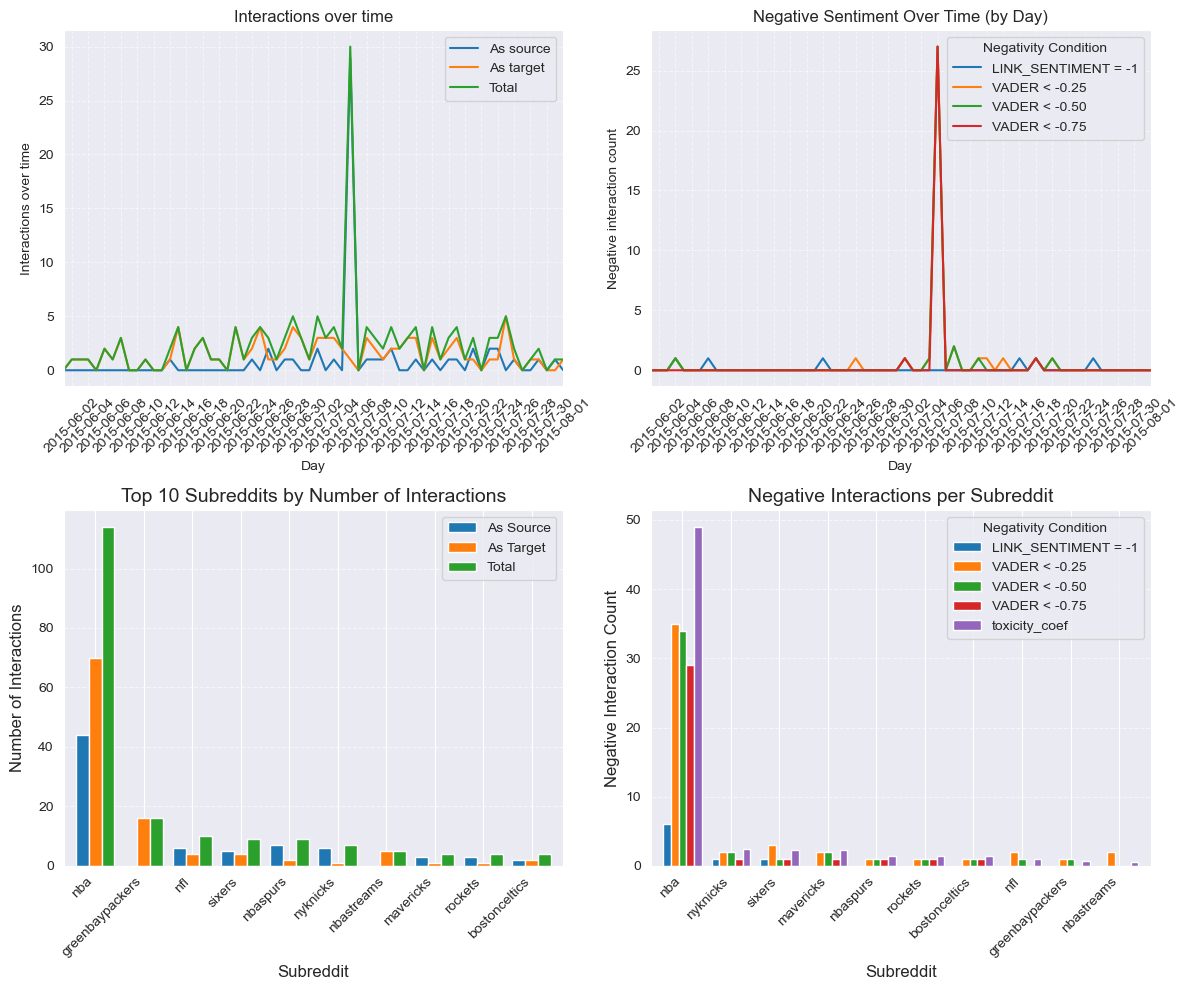

In [137]:
# Plot relevant graphs
fig, axes = plt.subplots(2, 2, figsize=(12, 10))

import matplotlib.dates as mdates

# Plot 1: Interactions over time 
daily_interactions.plot(x="DAY", y="source_interaction_count", title="Interactions over time", ax=axes[0][0])
daily_interactions.plot(x="DAY", y="target_interaction_count", ax=axes[0][0])
daily_interactions.plot(x="DAY", y="total_interaction_count", ax=axes[0][0])
axes[0][0].set_xlabel("Day")
axes[0][0].set_xlim(time_window)
axes[0][0].legend(["As source", "As target", "Total"])
axes[0][0].set_ylabel("Interactions over time")
axes[0][0].grid(True, linestyle="--", alpha=0.5)

axes[0][0].xaxis.set_major_locator(mdates.DayLocator(interval=2))
axes[0][0].xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m-%d"))
axes[0][0].tick_params(axis="x", rotation=45)


# Plot 2: Negative sentiment over time
daily_neg_sentiment_body_ls.plot(title="Negative Sentiment Over Time (by Day)", ax=axes[0][1])
daily_neg_sentiment_body_25.plot(ax=axes[0][1])
daily_neg_sentiment_body_50.plot(ax=axes[0][1])
daily_neg_sentiment_body_75.plot(ax=axes[0][1])
axes[0][1].set_xlabel("Day")
axes[0][1].set_xlim(time_window)
axes[0][1].set_ylabel("Negative interaction count")
axes[0][1].legend(labels=[
    "LINK_SENTIMENT = -1",
    "VADER < -0.25",
    "VADER < -0.50",
    "VADER < -0.75"
], title="Negativity Condition")
axes[0][1].grid(True, linestyle="--", alpha=0.5)

axes[0][1].xaxis.set_major_locator(mdates.DayLocator(interval=2))
axes[0][1].xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m-%d"))
axes[0][1].tick_params(axis="x", rotation=45)


# Plot 3: Subreddits interactions as target or source
top10 = interaction_counts.head(10)[["source_interactions", "target_interactions", "total_interactions"]]
top10.plot(
    kind="bar",
    width=0.8, 
    ax=axes[1][0]
)
axes[1][0].set_title("Top 10 Subreddits by Number of Interactions", fontsize=14)
axes[1][0].set_xlabel("Subreddit", fontsize=12)
axes[1][0].set_ylabel("Number of Interactions", fontsize=12)
axes[1][0].set_xticks(range(len(top10.index)))
axes[1][0].set_xticklabels(top10.index, rotation=45, ha="right")
axes[1][0].legend(["As Source", "As Target", "Total"])
axes[1][0].grid(axis="y", linestyle="--", alpha=0.6)


# Plot 4: Subreddits interactions positive or negative
neg_counts.plot(
    kind="bar",
    ax=axes[1][1],
    width=0.8,
)

axes[1][1].set_title("Negative Interactions per Subreddit", fontsize=14)
axes[1][1].set_xlabel("Subreddit", fontsize=12)
axes[1][1].set_ylabel("Negative Interaction Count", fontsize=12)
axes[1][1].set_xticks(range(len(neg_counts.index)))
axes[1][1].set_xticklabels(neg_counts.index, rotation=45, ha="right")
axes[1][1].legend(title="Negativity Condition")
axes[1][1].grid(axis="y", linestyle="--", alpha=0.6)

plt.tight_layout()
plt.show()

## Emergence without major trigger